# RT-IoT2022 — Intrusion Detection on IoT Network Traffic
## AI & Machine Learning Mini-Project — Deliverable 2: V1 Notebook

**Course:** AI & Machine Learning — LCE3_IoT3 (2026-2027) — Instructor: Faouzi MOUSSA

**Group members:**

| # | Last name | First name |
|---|-----------|------------|
| 1 | Ben Abderrazak | Mohamed Rached |
| 2 | Hasnaoui | Yasmine |
| 3 | Smaili | Ahmed |
| 4 | Zammouri | Mohamed Chrif |



## 1. Problem and objective

**IoT context.** Connected devices (sensors, smart bulbs, MQTT gateways…) have limited resources and are easy targets: flooding attacks (DoS/DDoS), ARP spoofing, port scans. An intrusion detection system must spot these behaviours from network traffic.

**What one observation is.** One row = **one network flow** (a communication between two machines), described by statistics such as duration, number of packets sent/received, payload volume, TCP flags and inter-packet times.

**Machine learning problem.** Supervised **binary classification**: predict whether a flow is
- `0` = **benign** (normal IoT traffic: MQTT, ThingSpeak, Wipro bulb);
- `1` = **attack** (SYN-flood DoS, Slowloris, Nmap scans, ARP poisoning).

The `label` target is derived from the `Attack_type` column .

**Objective of V1.** Build a first simple model, evaluated properly, and understand what it gets right and wrong.

**Which errors cost most?** In a security system, a **missed attack** (false negative) is worse than a **false alarm** (false positive), but too many false alarms make the system unusable. We therefore track **recall** and **precision**, not only accuracy.

## 2. Data loading and source


**Access.** The notebook reads `./Data/dataset.csv` (relative to the notebook folder); no download is performed.

**Building the `label` target.** Traffic types whose name contains `mqtt`, `thing` or `wipro` (MQTT_Publish, Thing_Speak, Wipro_bulb) are **benign** (`0`); all other types are **attacks** (`1`).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
import sklearn

RANDOM_STATE = 42          # single seed: reproducible results
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100

In [2]:
DATA_PATH = Path("../Data/dataset.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}.\n"
        "Place dataset.csv in the Data folder (one level above the notebook folder)."
    )

raw_df = pd.read_csv(DATA_PATH)
raw_df = raw_df.loc[:, ~raw_df.columns.str.contains("^Unnamed")]   # useless index column

# Binary target derived from Attack_type
NORMAL_KEYS = ("mqtt", "thing", "wipro")
is_normal = raw_df["Attack_type"].str.lower().str.contains("|".join(NORMAL_KEYS), na=False)
raw_df["label"] = (~is_normal).astype(int)

print(f"Observations (flows): {raw_df.shape[0]:,}")
print(f"Columns             : {raw_df.shape[1]}")
raw_df[["Attack_type", "label"]].drop_duplicates().sort_values("label")

Observations (flows): 123,117
Columns             : 85


,Attack_type,label
0,MQTT_Publish,0
4146,Thing_Speak,0
12254,Wipro_bulb,0
12507,ARP_poisioning,1
20257,DDOS_Slowloris,1
20791,DOS_SYN_Hping,1
115450,Metasploit_Brute_Force_SSH,1
115487,NMAP_FIN_SCAN,1
115515,NMAP_OS_DETECTION,1
117515,NMAP_TCP_scan,1


The table above checks the target rule: each traffic type maps to a single `label` value.

## 3. Data exploration

### 3.1 Variables used

The dataset contains about sixty flow statistics. For this V1 we keep **8 numerical variables** describing the duration, volume, rhythm and TCP signalling of a flow (introduced in the L1 notebook):

| Variable | What it measures |
|---|---|
| `flow_duration` | flow duration |
| `fwd_pkts_tot` / `bwd_pkts_tot` | packets sent / received |
| `flow_pkts_per_sec` | traffic intensity |
| `flow_pkts_payload.tot` | total payload volume |
| `flow_SYN_flag_count` | number of SYN flags (connection opening) |
| `flow_ACK_flag_count` | number of ACK flags (acknowledgements) |
| `flow_iat.avg` | average time between two packets |

The **ports** (`id.orig_p`, `id.resp_p`) are not used: they are identifiers rather than behaviour measurements, and a model could simply memorize them.

In [3]:
MAIN_FEATURES = [
    "flow_duration", "fwd_pkts_tot", "bwd_pkts_tot", "flow_pkts_per_sec",
    "flow_pkts_payload.tot", "flow_SYN_flag_count", "flow_ACK_flag_count", "flow_iat.avg",
]
missing_features = [c for c in MAIN_FEATURES if c not in raw_df.columns]
assert not missing_features, f"Missing columns: {missing_features}"

print("Column types:", raw_df.dtypes.value_counts().to_dict())
display(raw_df[MAIN_FEATURES].describe().T)

Column types: {dtype('float64'): 56, dtype('int64'): 26, <StringDtype(na_value=nan)>: 3}


,count,mean,std,min,25%,50%,75%,max
flow_duration,123117.0,3.8096,130.0054,0.0,1.0000e-06,4.0000e-06,5.0000e-06,2.1728e+04
fwd_pkts_tot,123117.0,2.2688,22.3366,0.0,1.0000e+00,1.0000e+00,1.0000e+00,4.3450e+03
bwd_pkts_tot,123117.0,1.9095,33.0183,0.0,1.0000e+00,1.0000e+00,1.0000e+00,1.0112e+04
flow_pkts_per_sec,123117.0,703568.2880,741563.4222,0.0,1.4909e+02,4.9345e+05,1.0486e+06,2.0972e+06
flow_pkts_payload.tot,123117.0,734.5172,42965.9917,0.0,1.2000e+02,1.2000e+02,1.2000e+02,1.3611e+07
flow_SYN_flag_count,123117.0,0.9509,0.4743,0.0,1.0000e+00,1.0000e+00,1.0000e+00,8.0000e+00
flow_ACK_flag_count,123117.0,2.6777,41.6549,0.0,1.0000e+00,1.0000e+00,1.0000e+00,1.1772e+04
flow_iat.avg,123117.0,139654.4860,874802.6415,0.0,9.5367e-01,4.0531e+00,5.0068e+00,7.2836e+07


**Reading.** For most variables the mean is far from the median and the maximum is much larger than the 75th percentile: the distributions are **strongly skewed**, with a few very large flows. This justifies the logarithmic scale used in the plots of section 3.3.

### 3.2 Class distribution

Before modelling, we need to know how many flows belong to each traffic type.

,Count,Percentage (%),label
Attack_type,,,
DOS_SYN_Hping,94659,76.89,1
Thing_Speak,8108,6.59,0
ARP_poisioning,7750,6.29,1
MQTT_Publish,4146,3.37,0
NMAP_UDP_SCAN,2590,2.10,1
NMAP_XMAS_TREE_SCAN,2010,1.63,1
NMAP_OS_DETECTION,2000,1.62,1
NMAP_TCP_scan,1002,0.81,1
DDOS_Slowloris,534,0.43,1



Binary target:
  label = 0 (benign): 12,507 flows (10.2%)
  label = 1 (attack): 110,610 flows (89.8%)


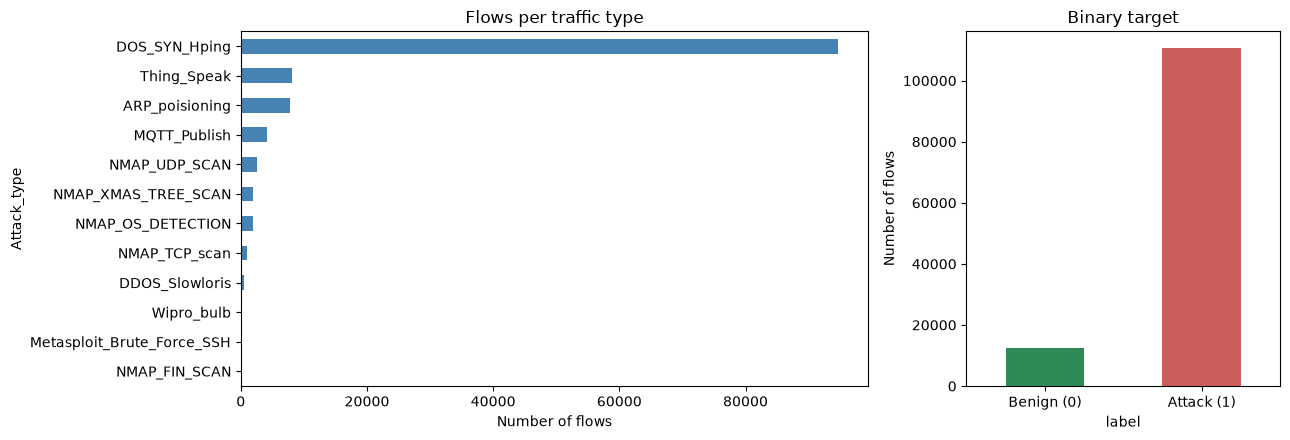

In [4]:
class_counts = raw_df["Attack_type"].value_counts()
class_table = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": (class_counts / len(raw_df) * 100).round(2),
    "label": raw_df.groupby("Attack_type")["label"].first().loc[class_counts.index],
})
display(class_table)

label_counts = raw_df["label"].value_counts().sort_index()
print("\nBinary target:")
for lab, n in label_counts.items():
    print(f"  label = {lab} ({'benign' if lab == 0 else 'attack'}): {n:,} flows ({n/len(raw_df):.1%})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})
class_counts.sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Flows per traffic type")
axes[0].set_xlabel("Number of flows")
label_counts.rename({0: "Benign (0)", 1: "Attack (1)"}).plot(kind="bar", ax=axes[1], color=["seagreen", "indianred"])
axes[1].set_title("Binary target")
axes[1].set_ylabel("Number of flows")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Comment.** The dataset is **highly imbalanced**:
- a single attack, `DOS_SYN_Hping`, accounts for about **77%** of all flows;
- benign flows are only about **10%** of the total, and `Wipro_bulb` is the rarest class (~0.2%).

Direct consequence: a "model" that always answers *attack* would reach about 90% accuracy while detecting nothing useful. Accuracy alone is therefore not enough (see sections 5 and 7).

### 3.3 Do the 8 variables differ between benign traffic and attacks?

Because the distributions are very spread out, we plot `log(1 + x)`. Each plot compares the two classes (normalized histograms, so that the difference in class sizes does not hide the shapes).

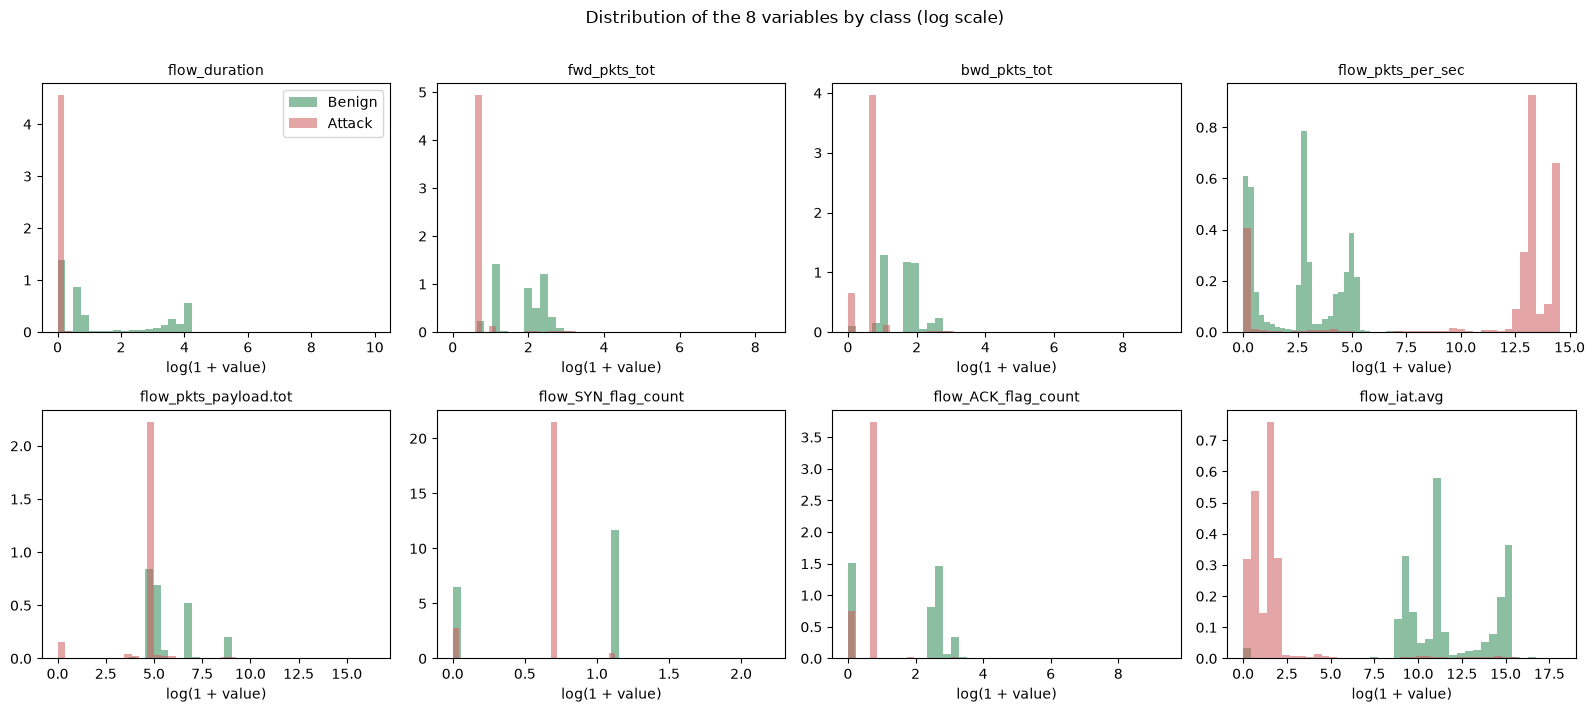

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), MAIN_FEATURES):
    for lab, name, color in [(0, "Benign", "seagreen"), (1, "Attack", "indianred")]:
        values = np.log1p(raw_df.loc[raw_df["label"] == lab, col].clip(lower=0))
        ax.hist(values, bins=40, alpha=0.55, density=True, label=name, color=color)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("log(1 + value)")
axes[0, 0].legend()
plt.suptitle("Distribution of the 8 variables by class (log scale)", y=1.01)
plt.tight_layout()
plt.show()

**Comment.** Variables whose two histograms **overlap little** separate the classes well; those where they are almost superimposed will carry little information. These plots give a first intuition that we will compare with the variable importance learned by the model (section 7.3). The visible differences suggest that even a simple model can already separate a large share of the flows.

### 3.4 Correlations between the selected variables



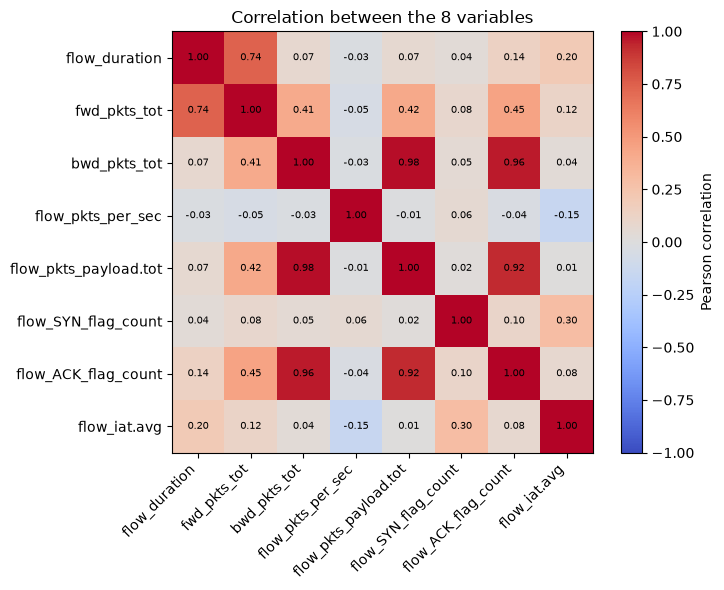

Strongly correlated pairs (|r| >= 0.8):
  bwd_pkts_tot  <->  flow_pkts_payload.tot : r = 0.98
  bwd_pkts_tot  <->  flow_ACK_flag_count : r = 0.96
  flow_pkts_payload.tot  <->  flow_ACK_flag_count : r = 0.92


In [6]:
corr = raw_df[MAIN_FEATURES].corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(MAIN_FEATURES)), MAIN_FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(MAIN_FEATURES)), MAIN_FEATURES)
for i in range(len(MAIN_FEATURES)):
    for j in range(len(MAIN_FEATURES)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation between the 8 variables")
plt.tight_layout()
plt.show()

pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(MAIN_FEATURES) for b in MAIN_FEATURES[i+1:] if abs(corr.loc[a, b]) >= 0.8]
print("Strongly correlated pairs (|r| >= 0.8):")
for a, b, r in pairs:
    print(f"  {a}  <->  {b} : r = {r:.2f}")
if not pairs:
    print("  none")

**Comment.** The pairs listed above are the ones that overlap most (for example, packet counts and data volume usually grow together). We keep them: redundancy does not hurt a decision tree.

### 3.5 Data quality

We check missing values, infinite values, exact duplicates, constant columns and extreme values.

In [7]:
num_raw = raw_df.select_dtypes(include=np.number)

n_missing = int(raw_df.isna().sum().sum())
n_inf = int(np.isinf(num_raw).sum().sum())
n_dup = int(raw_df.duplicated().sum())
constant_cols = [c for c in raw_df.columns if raw_df[c].nunique(dropna=False) <= 1]

quality = pd.DataFrame({
    "Check": ["Missing cells", "Infinite values", "Exact duplicate rows", "Constant columns"],
    "Result": [n_missing, n_inf, f"{n_dup:,} ({n_dup/len(raw_df):.2%})", f"{len(constant_cols)}: {constant_cols}"],
})
display(quality)

# Extreme values (IQR rule), exploratory only
num_for_iqr = num_raw.drop(columns=["id.orig_p", "id.resp_p", "label"], errors="ignore")
q1, q3 = num_for_iqr.quantile(0.25), num_for_iqr.quantile(0.75)
iqr = q3 - q1
outliers = num_for_iqr.lt(q1 - 1.5 * iqr) | num_for_iqr.gt(q3 + 1.5 * iqr)
print(f"Numerical variables analysed: {num_for_iqr.shape[1]}")
print(f"Rows with at least one extreme value (IQR): {int(outliers.any(axis=1).sum()):,} ({outliers.any(axis=1).mean():.1%})")

,Check,Result
0,Missing cells,0
1,Infinite values,0
2,Exact duplicate rows,"5,195 (4.22%)"
3,Constant columns,1: ['bwd_URG_flag_count']


Numerical variables analysed: 79
Rows with at least one extreme value (IQR): 38,295 (31.1%)


**Comment.**
- No missing or infinite values: imputation will not actually be needed, but we keep a median imputer in the pipeline as a safeguard (section 6).
- **Exact duplicates** exist (about 4%): we remove them (section 4), because identical rows present in both train and test would distort the evaluation.
- One column is constant (`bwd_URG_flag_count`): it carries no information. It is not among our 8 variables, so no action is needed.
- About **one third of the flows** contain at least one "extreme" value according to the IQR rule. In network traffic these values are often precisely the attacks (packet bursts): **we do not remove them**.

## 4. Data preparation

Each transformation is justified:

| # | Transformation | Justification |
|---|---|---|
| 1 | Replace ±∞ with `NaN` | Infinite values (e.g. division by a zero duration) cannot be used by a model. There are none here, but the step protects the pipeline. |
| 2 | Remove exact duplicates | Prevent the same row from appearing in both train and test. |
| 3 | Keep only the 8 explanatory variables | Follow the guideline  and stay interpretable. |
| 4 | **Exclude** `Attack_type` and the ports from the inputs | `label` is built from `Attack_type`: using it would be **data leakage** (the model would "read" the answer). |
| 5 | Median imputation (inside the pipeline, fitted on train) | Avoids any information leaking from test to train. |
| 6 | No scaling | Decision trees do not depend on the scale of the variables. |
| 7 | Keep extreme values | They carry an attack signal . |

`Attack_type` is kept aside, **only** to analyse errors in section 7.4.

In [8]:
clean_df = raw_df.replace([np.inf, -np.inf], np.nan)         
n_before = len(clean_df)
clean_df = clean_df.drop_duplicates()                           
print(f"Duplicates removed: {n_before - len(clean_df):,}")
print(f"Size before: {raw_df.shape} | after: {clean_df.shape}")

X = clean_df[MAIN_FEATURES].copy()      
y = clean_df["label"].copy()            
attack_type = clean_df["Attack_type"]   

assert "Attack_type" not in X.columns and "label" not in X.columns   
print("Input variables:", list(X.columns))

Duplicates removed: 5,195
Size before: (123117, 85) | after: (117922, 85)
Input variables: ['flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'flow_pkts_per_sec', 'flow_pkts_payload.tot', 'flow_SYN_flag_count', 'flow_ACK_flag_count', 'flow_iat.avg']


## 5. Evaluation setup

**Train / test split.** 80% of the flows for training, 20% for testing, **stratified** on `label` to keep the same benign/attack proportion in both parts. The test set is used **only for the final measurement**: no tuning is done with it.

**Balancing the train set only.** The train set is highly imbalanced (~90% attacks). We randomly reduce the majority class to the size of the minority class (*undersampling*). The **test set keeps its natural distribution**, so that the model is evaluated in realistic conditions. Trade-off: part of the attack examples is discarded from training.

**No temporal split.** The dataset has no usable date column, so we use a random split.

**Simple reference.** To know whether the model brings anything, we compare it with a "naive" classifier that always predicts the most frequent class of the train set (*attack*).

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
attack_type_test = attack_type.loc[X_test.index]   # for error analysis (section 7.4)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
display(pd.DataFrame({
    "Train (natural)": y_train.value_counts().sort_index(),
    "Test (natural)": y_test.value_counts().sort_index(),
}).rename_axis("label"))

Train: (94337, 8) | Test: (23585, 8)


,Train (natural),Test (natural)
label,,
0,9612,2403
1,84725,21182


In [10]:
# Balance the train set by undersampling the majority class
n_min = y_train.value_counts().min()
idx_balanced = (
    y_train.groupby(y_train, group_keys=False)
           .apply(lambda s: s.sample(n=n_min, random_state=RANDOM_STATE))
           .index
)
X_train_bal = X_train.loc[idx_balanced].sample(frac=1, random_state=RANDOM_STATE)   # shuffle
y_train_bal = y_train.loc[X_train_bal.index]

print(f"Balanced train set: {X_train_bal.shape}")
display(pd.DataFrame({
    "Train (natural)": y_train.value_counts().sort_index(),
    "Train (balanced)": y_train_bal.value_counts().sort_index(),
    "Test (unchanged)": y_test.value_counts().sort_index(),
}).rename_axis("label"))

Balanced train set: (19224, 8)


,Train (natural),Train (balanced),Test (unchanged)
label,,,
0,9612,9612,2403
1,84725,9612,21182


In [11]:
# Naive reference: always the most frequent class of the natural train set (= attack)
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
print("Class predicted by the naive reference:", baseline.predict(X_test.head(1))[0], "(1 = attack)")

Class predicted by the naive reference: 1 (1 = attack)


## 6. First model: Decision Tree

**Why a decision tree?**
- it is a **simple and readable** model: the learned rules can be displayed;
- it needs **no scaling or transformation** of the very skewed variables;
- it provides a **variable importance**, to check consistency with the exploration of section 3.

**Hyperparameters.** We limit the depth to `max_depth=5`: deep enough to capture useful rules, shallow enough for the tree to stay readable and not memorize the training set. This value is fixed *a priori*, without using the test set.

In [12]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),            # fitted on train only
    ("tree", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)),
])
model.fit(X_train_bal, y_train_bal)

tree = model.named_steps["tree"]
print("Model trained on", len(X_train_bal), "balanced flows.")
print("Tree depth:", tree.get_depth(), "| number of leaves:", tree.get_n_leaves())

Model trained on 19224 balanced flows.
Tree depth: 5 | number of leaves: 28


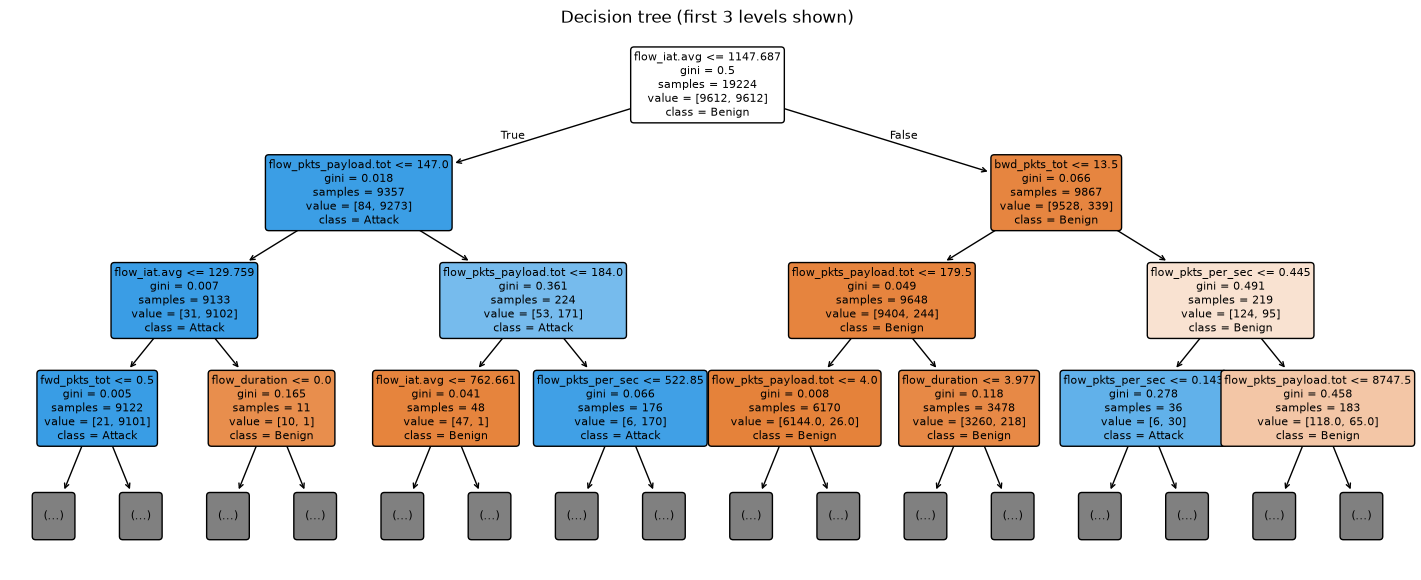

In [13]:
# The first 3 levels of the tree: the learned rules
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(tree, max_depth=3, feature_names=MAIN_FEATURES,
          class_names=["Benign", "Attack"], filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Decision tree (first 3 levels shown)")
plt.show()

**Reading the tree.** Each node asks a question such as "*variable ≤ threshold?*" and splits the flows into two groups; the colour shows the majority class of the node. Variables appearing **at the top** of the tree are those that best separate the two classes on the training set.

## 7. Evaluation on the test set

We evaluate the model and the naive reference **on the same, non-balanced test set**. Metrics used:
- **Accuracy**: share of correctly classified flows (misleading here, see 3.2);
- **Balanced accuracy**: average of the recalls of the two classes;
- **Precision (attack)**: among flows flagged as attacks, the share that really are;
- **Recall (attack)**: among real attacks, the share detected;
- **Recall (benign)**: among normal flows, the share left alone (1 − false alarm rate);
- **F1** and **ROC-AUC**: summaries of overall quality.

In [14]:
y_pred_model = model.predict(X_test)
y_score_model = model.predict_proba(X_test)[:, 1]
y_pred_base = baseline.predict(X_test)
y_score_base = baseline.predict_proba(X_test)[:, 1]

def evaluate(name, y_true, y_pred, y_score):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision (attack)": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall (attack)": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1 (attack)": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Precision (benign)": precision_score(y_true, y_pred, pos_label=0, zero_division=0),
        "Recall (benign)": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "F1 (benign)": f1_score(y_true, y_pred, pos_label=0, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_score),
    }

results = pd.DataFrame([
    evaluate("Naive reference (always attack)", y_test, y_pred_base, y_score_base),
    evaluate("Decision Tree (depth 5)", y_test, y_pred_model, y_score_model),
]).set_index("Model").round(4)
display(results.T)

print("Detailed report of the model:")
print(classification_report(y_test, y_pred_model, target_names=["Benign (0)", "Attack (1)"], digits=4))

Model,Naive reference (always attack),Decision Tree (depth 5)
Accuracy,0.8981,0.9768
Balanced accuracy,0.5000,0.9817
Precision (attack),0.8981,0.9986
Recall (attack),1.0000,0.9755
F1 (attack),0.9463,0.9869
Precision (benign),0.0000,0.8209
Recall (benign),0.0000,0.9879
F1 (benign),0.0000,0.8967
ROC-AUC,0.5000,0.9956


Detailed report of the model:
              precision    recall  f1-score   support

  Benign (0)     0.8209    0.9879    0.8967      2403
  Attack (1)     0.9986    0.9755    0.9869     21182

    accuracy                         0.9768     23585
   macro avg     0.9097    0.9817    0.9418     23585
weighted avg     0.9805    0.9768    0.9777     23585



**How to read this table.** The naive reference gets a high accuracy only because ~90% of the test set is attacks, but its **recall on the benign class is zero**: it recognizes no normal traffic. The model is useful only if it keeps a good recall on attacks **and** clearly improves recall and precision on benign flows. The comparison of *balanced accuracy*, *benign recall* and *benign F1* is therefore the informative one, not accuracy.

### 7.1 Confusion matrices

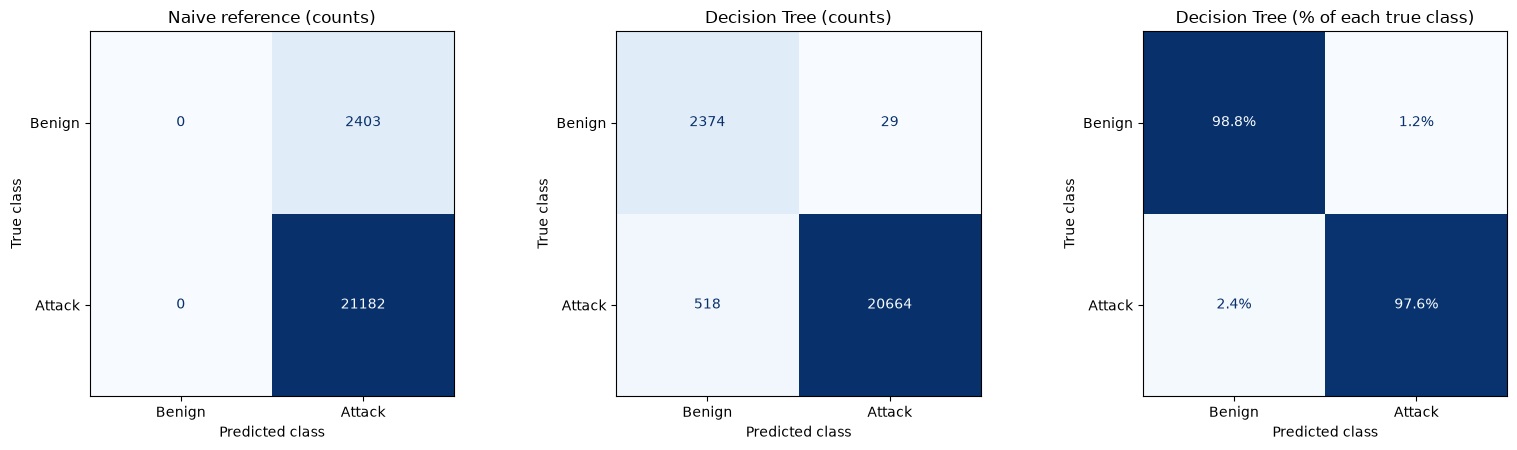

True negatives (benign recognized)  : 2,374
False positives (false alarms)      : 29
False negatives (missed attacks)    : 518
True positives (attacks detected)   : 20,664


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
labels = ["Benign", "Attack"]
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_base, display_labels=labels, ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Naive reference (counts)")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_model, display_labels=labels, ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Decision Tree (counts)")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_model, display_labels=labels, ax=axes[2], cmap="Blues",
                                        normalize="true", values_format=".1%", colorbar=False)
axes[2].set_title("Decision Tree (% of each true class)")
for ax in axes:
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
plt.tight_layout()
plt.show()

tn = int(((y_test == 0) & (y_pred_model == 0)).sum()); fp = int(((y_test == 0) & (y_pred_model == 1)).sum())
fn = int(((y_test == 1) & (y_pred_model == 0)).sum()); tp = int(((y_test == 1) & (y_pred_model == 1)).sum())
print(f"True negatives (benign recognized)  : {tn:,}")
print(f"False positives (false alarms)      : {fp:,}")
print(f"False negatives (missed attacks)    : {fn:,}")
print(f"True positives (attacks detected)   : {tp:,}")

**Comment.** The left matrix shows the naive reference: the whole "Benign" column is empty. For the tree, the normalized matrix (right) is the most telling, because it gives the **recall of each class** independently of class size. The two error types do not have the same cost: a **false negative** is an attack that goes unnoticed, a **false positive** is a needless alert for the administrator.

### 7.2 ROC curve and overfitting check

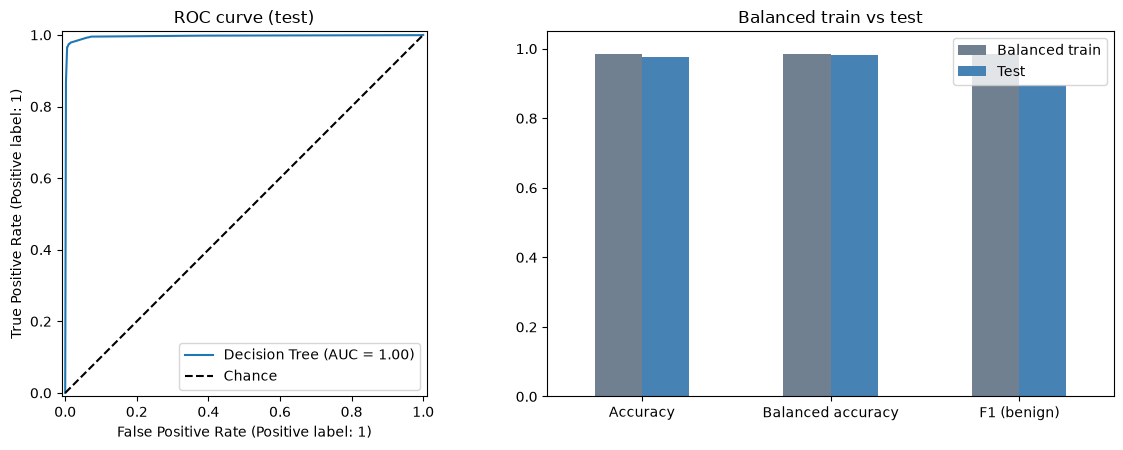

,Balanced train,Test
Accuracy,0.9859,0.9768
Balanced accuracy,0.9859,0.9817
F1 (benign),0.9860,0.8967


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

RocCurveDisplay.from_predictions(y_test, y_score_model, ax=axes[0], name="Decision Tree")
axes[0].plot([0, 1], [0, 1], "k--", label="Chance")
axes[0].set_title("ROC curve (test)")
axes[0].legend(loc="lower right")

# Balanced train vs test: a large gap would signal overfitting
train_bal_pred = model.predict(X_train_bal)
comp = pd.DataFrame({
    "Balanced train": [accuracy_score(y_train_bal, train_bal_pred), balanced_accuracy_score(y_train_bal, train_bal_pred), f1_score(y_train_bal, train_bal_pred, pos_label=0)],
    "Test": [accuracy_score(y_test, y_pred_model), balanced_accuracy_score(y_test, y_pred_model), f1_score(y_test, y_pred_model, pos_label=0)],
}, index=["Accuracy", "Balanced accuracy", "F1 (benign)"])
comp.plot(kind="bar", ax=axes[1], color=["slategray", "steelblue"], ylim=(0, 1.05))
axes[1].set_title("Balanced train vs test")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
display(comp.round(4))

**Comment.** The ROC curve is better the closer it gets to the top-left corner (many attacks detected for few false alarms). The right plot compares train and test scores: a large gap would indicate that the tree memorizes the training set. Note that F1 (benign) can differ between train and test simply because the test set contains far fewer benign flows relative to attacks, so precision on the benign class is naturally lower there.

### 7.3 Variable importance

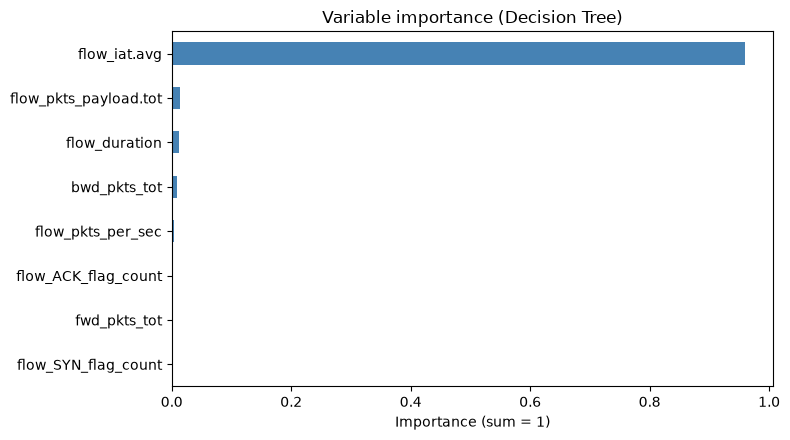

,Importance
flow_iat.avg,0.9593
flow_pkts_payload.tot,0.0140
flow_duration,0.0127
bwd_pkts_tot,0.0096
flow_pkts_per_sec,0.0032
flow_ACK_flag_count,0.0007
fwd_pkts_tot,0.0004
flow_SYN_flag_count,0.0001


In [17]:
importances = pd.Series(tree.feature_importances_, index=MAIN_FEATURES).sort_values()
ax = importances.plot(kind="barh", figsize=(8, 4.5), color="steelblue")
ax.set_title("Variable importance (Decision Tree)")
ax.set_xlabel("Importance (sum = 1)")
plt.tight_layout()
plt.show()
display(importances.sort_values(ascending=False).to_frame("Importance").round(4))

**Comment.** Importance measures how much each variable contributes to reducing impurity across the splits of the tree. The top variables are the ones the model relies on most; we compare them with the observations of section 3.3 (variables whose distributions differ most between classes). Caution: when two variables are strongly correlated (3.4), the tree picks one and the other can look artificially unimportant, so each may look less important than it really is.

### 7.4 Where does the model make mistakes? Analysis by traffic type

The dataset contains 10 traffic types. Grouping them into two classes hides differences, so we look at the error rate of each original type (on the test set). For an attack, an error is a **missed attack**; for benign traffic, an error is a **false alarm**.

,label,test_flows,errors,error_rate,error_nature
type,,,,,
Metasploit_Brute_Force_SSH,1,6,5,0.8333,missed attack
ARP_poisioning,1,1542,500,0.3243,missed attack
Wipro_bulb,0,47,8,0.1702,false alarm
DDOS_Slowloris,1,116,5,0.0431,missed attack
Thing_Speak,0,1564,19,0.0121,false alarm
NMAP_UDP_SCAN,1,551,4,0.0073,missed attack
NMAP_XMAS_TREE_SCAN,1,451,3,0.0067,missed attack
NMAP_TCP_scan,1,210,1,0.0048,missed attack
MQTT_Publish,0,792,2,0.0025,false alarm


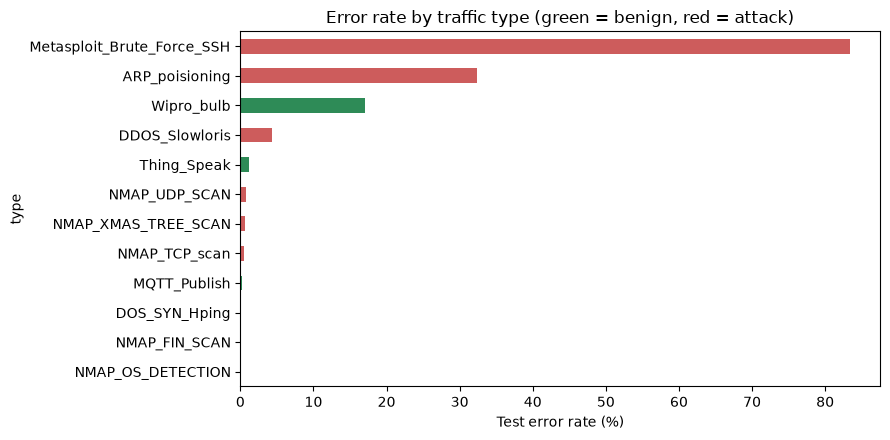

In [18]:
err = pd.DataFrame({"type": attack_type_test, "y_true": y_test, "y_pred": y_pred_model})
err["error"] = (err["y_true"] != err["y_pred"])
by_type = (err.groupby("type")
              .agg(label=("y_true", "first"), test_flows=("error", "size"), errors=("error", "sum"), error_rate=("error", "mean"))
              .sort_values("error_rate", ascending=False))
by_type["error_nature"] = np.where(by_type["label"] == 1, "missed attack", "false alarm")
display(by_type.round(4))

order = by_type["error_rate"].sort_values().index
colors = by_type["label"].map({0: "seagreen", 1: "indianred"}).loc[order]
ax = (by_type["error_rate"].loc[order] * 100).plot(kind="barh", figsize=(9, 4.5), color=colors)
ax.set_xlabel("Test error rate (%)")
ax.set_title("Error rate by traffic type (green = benign, red = attack)")
plt.tight_layout()
plt.show()

**Comment.** This plot shows **which traffic types the model confuses**. Rare types (e.g. `Wipro_bulb`, `DDOS_Slowloris`) have few examples in the test set, so their error rate is statistically less reliable.